# CV Project 2 — Gradient Domain Editing và Ghép ảnh toàn cảnh

Notebook bám theo các slide **Chap 05** (ghép/hòa trộn ảnh, gradient domain), **Chap 08** (đặc trưng cục bộ, so khớp), **Chap 04** (warping, homography) và **Chap 03** (gradient) và đề `docs/CV-project-2.pdf`.

| Phần của đề | Nội dung | Slide tương ứng |
|---|---|---|
| **Phần 1** — Gradient Domain Editing | alpha/feather → pyramid → gradient domain (1-D) → Poisson 2-D; so sánh với ghép trực tiếp; đường cắt tối ưu | Chap 05 (s.6–25, 26–40) |
| **Phần 2** — Panorama | Harris → mô tả SIFT/ORB → ratio test, ROC → homography + RANSAC → warp → blending; so sánh SIFT/ORB bằng sai số căn chỉnh so với *ground truth* | Chap 08 (s.14–62), Chap 04 (s.27–44), Chap 05 (s.8) |

Code đầy đủ ở `src/` (`p2_gradient_domain.py`, `p2_panorama.py`, và các hàm hiện thực lại theo slide trong `slides_ch05_08.py`, `slides_ch02_04.py`). Notebook gọi lại các module thay vì chép code.

## Setup

In [1]:
# Colab only: clone the repo so src/ is available, then cd into it.
# !git clone https://github.com/nghoang1162050/CO3057-BTL_17.git repo && %cd repo
# !pip install -q -r requirements.txt

import os, sys, time
for cand in ("src", os.path.join("..", "src")):          # works from the repo root or from notebooks/
    if os.path.isdir(cand):
        SRC_DIR = os.path.abspath(cand)
        break
if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)

import numpy as np
import matplotlib.pyplot as plt
import cv2

plt.rcParams["figure.dpi"] = 70


def show(images, titles=None, ncols=None, size=4.0, cmap="gray"):
    """Display a row/grid of images. uint8 gray images use a fixed 0-255
    window, float images are auto-scaled."""
    n = len(images)
    ncols = ncols or n
    nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows * 0.95))
    axes = np.atleast_1d(axes).ravel()
    for ax, im, t in zip(axes, images, titles or [""] * n):
        if im.ndim == 2:
            kw = dict(vmin=0, vmax=255) if im.dtype == np.uint8 else {}
            ax.imshow(im, cmap=cmap, **kw)
        else:
            ax.imshow(im)
        ax.set_title(t, fontsize=10)
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

from utils import to_gray3
import p2_gradient_domain as gde
import p2_panorama as pano
import slides_ch02_04 as sl
import slides_ch05_08 as s58

print("OpenCV:", cv2.__version__)

OpenCV: 5.0.0


**Ảnh sử dụng.** Cả hai phần mặc định dùng đầu vào *tổng hợp, tái lập được* (không cần tải về): cặp ảnh nền/đối tượng cho Phần 1 và một cảnh rộng ghép từ ảnh mẫu `scikit-image`, cắt thành 4 view chồng lấn với biến đổi phối cảnh nhẹ cho Phần 2. Điểm lợi của dữ liệu tổng hợp: **biết chính xác homography thật**, nên đánh giá được độ chính xác căn chỉnh *bằng số* chứ không chỉ bằng mắt. Muốn dùng ảnh riêng: bỏ vào `data/p2_gradient_domain/` và `data/p2_panorama/` (xem README trong các thư mục đó).

---
## Phần 1 — Gradient Domain Editing

### 1.1 Từ alpha blending tới pyramid blending (Chap 05, slide 6–9)

Quy trình ghép: (1) tách đối tượng (sprite) bằng mask, (2) hòa trộn vào ảnh nền. Hòa trộn đơn giản nhất là **alpha blending / feathering**
$$I_{blend}=\alpha I_{left}+(1-\alpha)I_{right}$$
Độ rộng vùng chuyển $\alpha$ là một đánh đổi: hẹp → còn đường nối, rộng → bóng mờ (ghost). **Pyramid blending** tách ảnh thành các dải tần (Laplacian pyramid) rồi trộn mỗi dải với mask được làm mờ theo tỷ lệ riêng: tần số thấp trộn trên vùng rộng, tần số cao trên vùng hẹp.

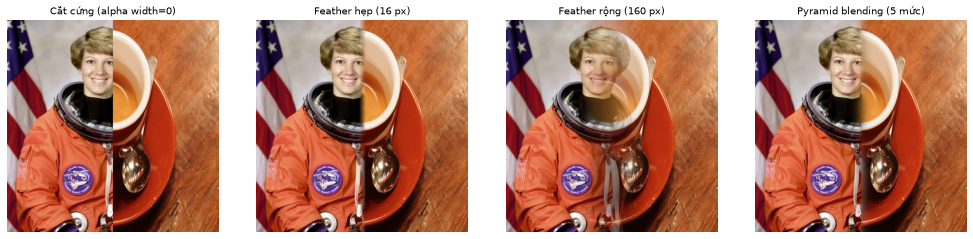

In [2]:
from skimage import data, img_as_ubyte
A = img_as_ubyte(data.astronaut())
B = cv2.resize(img_as_ubyte(data.coffee()), (512, 512), interpolation=cv2.INTER_AREA)

results = {"Cắt cứng (alpha width=0)": s58.alpha_blend(A, B, s58.horizontal_ramp(512, 512, 0)),
           "Feather hẹp (16 px)": s58.alpha_blend(A, B, s58.horizontal_ramp(512, 512, 16)),
           "Feather rộng (160 px)": s58.alpha_blend(A, B, s58.horizontal_ramp(512, 512, 160)),
           "Pyramid blending (5 mức)": s58.pyramid_blend(A, B, (s58.horizontal_ramp(512, 512, 0) > 0.5).astype(np.float32), levels=5)}
show(list(results.values()), list(results.keys()), size=3.6)

**Nhận xét.** Hai ảnh này khác nhau hoàn toàn về nội dung và màu nên không có cách trộn "đúng" tuyệt đối, nhưng sự đánh đổi hiện rõ: *cắt cứng* để lộ đường nối thẳng; *feather hẹp* làm mềm đường nối nhưng vẫn thấy ranh giới; *feather rộng* xóa ranh giới nhưng tạo bóng ma (khuôn mặt và tách cà phê chồng lên nhau); *pyramid* trộn các dải tần thấp trên vùng rộng và tần số cao trên vùng hẹp nên chuyển tiếp màu êm mà chi tiết mỗi bên không bị hai lớp chồng nặng như feather rộng. Tuy vậy các phương pháp này đều trộn **giá trị pixel**, nên không giải quyết được chênh lệch màu/ánh sáng — đó là động lực của gradient domain.

### 1.2 Gradient domain: ý tưởng trong 1-D (Chap 05, slide 10–15)

Pyramid blending vẫn để lộ biên qua nhiều dải tần. Gradient domain chuyển sang biểu diễn bằng **đạo hàm**: đạo hàm mô tả thay đổi cục bộ ở *mọi* tần số và ảnh được phục hồi (sai khác một hằng số) bằng tích phân. Quy trình: **vi phân → sao chép/trộn/chỉnh → tái tích phân**.

Mô phỏng 1-D: chèn vào tín hiệu nền *sáng* một đoạn từ tín hiệu *tối* có chứa một "chi tiết" (cái bướu). Dán trực tiếp giữ giá trị tuyệt đối → có bước nhảy ở hai đầu. Gradient domain chỉ giữ **đạo hàm của nguồn** và ghim hai đầu về giá trị của nền, nên bước nhảy biến mất mà chi tiết vẫn còn. Slide 15 cảnh báo: *không thể giữ trung thành mọi gradient* nếu điều kiện biên mâu thuẫn; ta thấy điều đó ở hình dưới (ô phải).

Bước nhảy tại biên trái/phải khi dán trực tiếp: -119.7 / 119.5
Bước nhảy khi gradient-domain:                0.1 / -0.2
Hình dạng 'chi tiết' được giữ? tương quan đạo hàm trong vùng chèn = 1.0


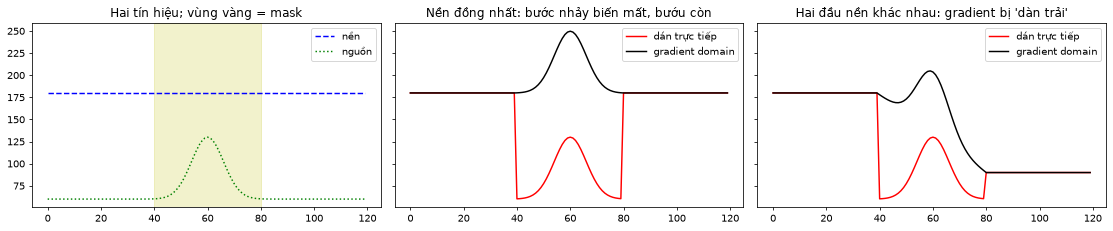

In [3]:
x = np.arange(120)
target = np.full(120, 180.0)                                   # nền sáng
source = np.full(120, 60.0)                                    # nguồn tối + một "chi tiết"
source += 70 * np.exp(-0.5 * ((x - 60) / 6.0) ** 2)
start, end = 40, 80

pasted = target.copy(); pasted[start:end] = source[start:end]
grad_blend = s58.blend_1d_gradient(target, source, start, end)
dx = lambda a: np.diff(a)
print("Bước nhảy tại biên trái/phải khi dán trực tiếp:", round(float(pasted[start] - pasted[start - 1]), 1), "/", round(float(pasted[end] - pasted[end - 1]), 1))
print("Bước nhảy khi gradient-domain:               ", round(float(grad_blend[start] - grad_blend[start - 1]), 1), "/", round(float(grad_blend[end] - grad_blend[end - 1]), 1))
print("Hình dạng 'chi tiết' được giữ? tương quan đạo hàm trong vùng chèn =",
      round(float(np.corrcoef(dx(grad_blend[start:end]), dx(source[start:end]))[0, 1]), 4))

# Trường hợp mâu thuẫn: hai đầu nền khác độ sáng nhưng nguồn phẳng-có-bướu => không giữ nổi mọi gradient
target2 = np.where(x < 60, 180.0, 90.0)
grad_conflict = s58.blend_1d_gradient(target2, source, start, end)
pasted2 = target2.copy(); pasted2[start:end] = source[start:end]

fig, axes = plt.subplots(1, 3, figsize=(16, 3.4), sharey=True)
axes[0].plot(target, "b--", label="nền"); axes[0].plot(source, "g:", label="nguồn"); axes[0].axvspan(start, end, color="y", alpha=.2); axes[0].legend(); axes[0].set_title("Hai tín hiệu; vùng vàng = mask")
axes[1].plot(pasted, "r", label="dán trực tiếp"); axes[1].plot(grad_blend, "k", label="gradient domain"); axes[1].legend(); axes[1].set_title("Nền đồng nhất: bước nhảy biến mất, bướu còn")
axes[2].plot(pasted2, "r", label="dán trực tiếp"); axes[2].plot(grad_conflict, "k", label="gradient domain"); axes[2].legend(); axes[2].set_title("Hai đầu nền khác nhau: gradient bị 'dàn trải'")
plt.tight_layout(); plt.show()

### 1.3 Poisson image editing trong 2-D (Chap 05, slide 16–25; Perez et al. 2003)

Trong 2-D lấy đạo hàm theo $x$ và $y$ rồi tái tích phân gặp vấn đề: $\int dx$ và $\int dy$ có thể không nhất quán, nên ta tìm nghiệm "ưng ý nhất" theo bình phương tối thiểu — tương đương giải **phương trình Poisson**:
$$\min_{f}\iint_{\Omega}\|\nabla f-\mathbf v\|^2\quad\text{với }f|_{\partial\Omega}=f^*|_{\partial\Omega},\qquad \mathbf v=\nabla g \text{ (gradient nguồn)}$$
Rời rạc, với mỗi pixel $p$ trong mask $\Omega$ và 4 lân cận $N(p)$:
$$4f(p)-\sum_{q\in N(p)}f(q)=4g(p)-\sum_{q\in N(p)}g(q)+\sum_{q\in N(p),\,q\notin\Omega}B(q)$$
Đây là hệ tuyến tính thưa $A\mathbf f=\mathbf b$ (slide 20–21: *least squares* với ma trận thưa), giải riêng cho từng kênh màu. Biến thể **mixed gradients** lấy gradient mạnh hơn giữa nguồn và nền ở mỗi điểm, phù hợp khi nguồn/nền đều có kết cấu.

[P2 Part1] No complete custom image set -- using the synthetic demo pair


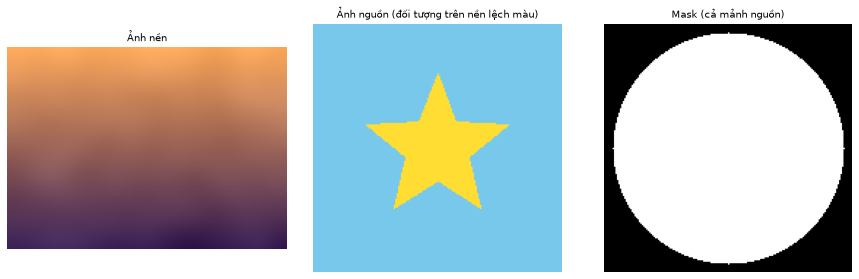

In [4]:
background, source, mask, offset = gde.load_pair()
show([background, source, to_gray3(mask)], ["Ảnh nền", "Ảnh nguồn (đối tượng trên nền lệch màu)", "Mask (cả mảnh nguồn)"], size=4.2)

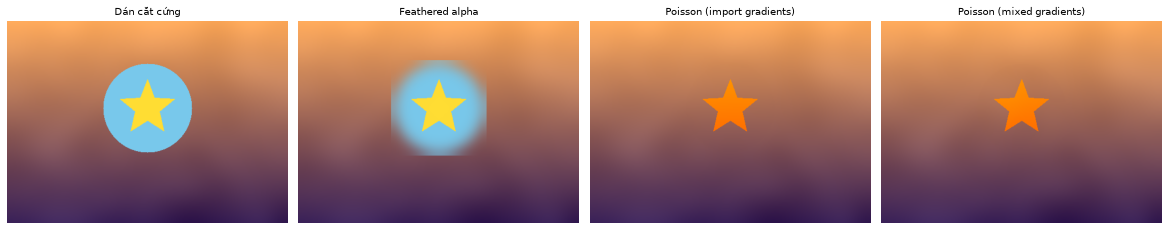

Giải Poisson: 19577 ẩn/kênh trong 66.5 ms (ma trận thưa)

phương pháp                     seam score  x so với nền   lệch màu trong/ngoài viền
nền gốc (tham chiếu)                  3.40          1.00                         0.1
Dán cắt cứng                         62.67         18.44                       182.1
Feathered alpha                      11.99          3.53                        18.7
Poisson (import gradients)            3.42          1.01                         0.9
Poisson (mixed gradients)             3.74          1.10                         0.9


In [5]:
naive = gde.naive_paste(background, source, mask, offset)
feather = gde.feathered_paste(background, source, mask, offset)
t0 = time.time(); poisson = gde.poisson_blend(background, source, mask, offset, mix_gradients=False); t_poisson = time.time() - t0
mixed = gde.poisson_blend(background, source, mask, offset, mix_gradients=True)

methods = {"Dán cắt cứng": naive, "Feathered alpha": feather, "Poisson (import gradients)": poisson, "Poisson (mixed gradients)": mixed}
show(list(methods.values()), list(methods.keys()), size=4.2)
print(f"Giải Poisson: {int(mask.sum() / 255)} ẩn/kênh trong {t_poisson * 1000:.1f} ms (ma trận thưa)")

# --- Đánh giá định lượng ---------------------------------------------------
full_mask = gde._full_size_mask(background.shape[:2], mask, offset)
ring = gde.boundary_ring(full_mask, radius=3)
inner = ring & (full_mask > 0); outer = ring & (full_mask == 0)
print(f"\n{'phương pháp':30s} {'seam score':>11s} {'x so với nền':>13s} {'lệch màu trong/ngoài viền':>27s}")
base = gde.seam_score(background, ring)
for name, im in [("nền gốc (tham chiếu)", background)] + list(methods.items()):
    step = float(np.linalg.norm(im[inner].mean(axis=0) - im[outer].mean(axis=0)))
    sc = gde.seam_score(im, ring)
    print(f"{name:30s} {sc:11.2f} {sc / base:13.2f} {step:27.1f}")

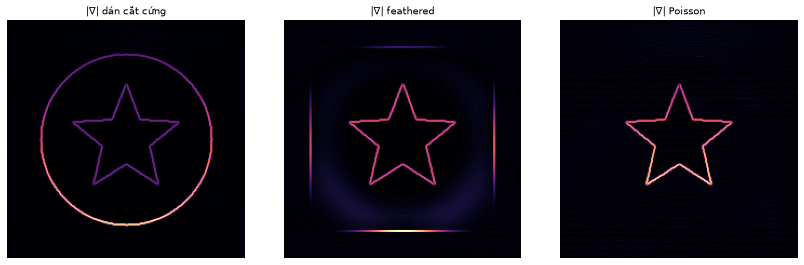

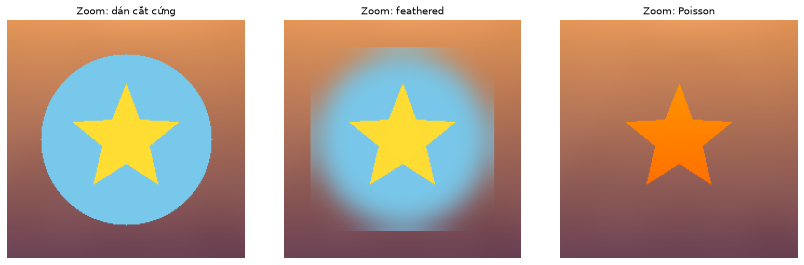

In [6]:
# Trực quan hóa gradient (slide 17): độ lớn gradient của ảnh ghép -- halo của cách dán trực tiếp hiện thành đường sáng
def grad_mag(im):
    g = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY).astype(np.float32)
    return np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
by0, bx0 = offset; sh, sw = mask.shape; pad = 25
crop = (slice(max(by0 - pad, 0), by0 + sh + pad), slice(max(bx0 - pad, 0), bx0 + sw + pad))
show([grad_mag(naive)[crop], grad_mag(feather)[crop], grad_mag(poisson)[crop]],
     ["|∇| dán cắt cứng", "|∇| feathered", "|∇| Poisson"], cmap="magma", size=4)
show([naive[crop], feather[crop], poisson[crop]], ["Zoom: dán cắt cứng", "Zoom: feathered", "Zoom: Poisson"], size=4)

**Nhận xét.**
- *Ghép trực trực tiếp* sao chép nguyên giá trị pixel của nguồn, nên nền phẳng khác màu của mảnh nguồn tạo **quầng (halo)** và một gradient rất lớn ở biên mask (ô "|∇|" và cột *seam score*/*lệch màu* ở trên). *Feathering* chỉ làm mềm chuyển tiếp nhưng vẫn trộn **giá trị**, nên quầng khác màu vẫn còn.
- *Poisson* giữ **gradient** của nguồn (viền ngôi sao sắc nét) còn vùng nền phẳng — gradient ≈ 0 — bị thay bằng màu nền xung quanh theo điều kiện biên; seam score về mức xấp xỉ chính ảnh nền. Đó là lý do đối tượng "ăn" vào ánh sáng của nền.
- *Mixed gradients* hữu ích khi nền cũng có kết cấu cần giữ (lấy gradient mạnh hơn); với nguồn phẳng như ở đây hai biến thể gần như giống nhau.
- **Hạn chế**: (i) màu của đối tượng bị kéo theo nền nên có thể đổi màu (mất "màu thật" của nguồn) — đúng cảnh báo slide 15; (ii) mask cắt qua vùng nhiều kết cấu vẫn để lại vệt; (iii) chi phí giải hệ thưa tăng theo diện tích mask.

### 1.4 "Don't blend, CUT!" — đường cắt tối ưu bằng quy hoạch động (Chap 05, slide 26–40)

Khi hai ảnh chồng lấn có vật thể di chuyển, trộn sẽ tạo **bóng ma (ghost)**. Thay vì trộn, chọn một **đường nối** đi qua nơi hai ảnh *giống nhau nhất*. Với đường dọc: $M(i,j)=E(i,j)+\min\big(M(i-1,j-1),M(i-1,j),M(i-1,j+1)\big)$, truy vết ngược từ ô nhỏ nhất ở hàng cuối (dynamic programming, giống seam carving). Ở đây $E$ là độ chênh bình phương giữa hai ảnh.

Tổng chi phí dọc đường nối:  thẳng giữa ảnh = 1.12e+05 | DP tối ưu = 1.19e+04


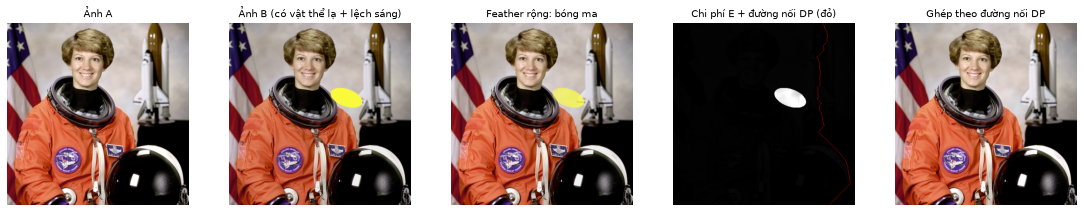

In [7]:
A = img_as_ubyte(data.astronaut())
Bimg = (A.astype(np.float32) * 0.94).astype(np.uint8)           # cùng cảnh, phơi sáng lệch nhẹ
cv2.ellipse(Bimg, (330, 210), (46, 24), 20, 0, 360, (250, 250, 60), -1)   # "vật thể di chuyển" chỉ có trong ảnh B
cost = ((A.astype(np.float32) - Bimg.astype(np.float32)) ** 2).sum(axis=2)
seam = s58.min_error_seam(cost)
cut = s58.seam_composite(A, Bimg, seam)
mid = s58.alpha_blend(A, Bimg, s58.horizontal_ramp(512, 512, 400))
vis_cost = np.clip(cost / np.percentile(cost, 99.5) * 255, 0, 255).astype(np.uint8)
vis_cost = cv2.cvtColor(vis_cost, cv2.COLOR_GRAY2RGB); vis_cost[np.arange(512), seam] = (255, 0, 0)

# So sánh: đường nối thẳng ở giữa vs đường nối DP
straight = np.full(512, 256)
total = lambda sm: float(cost[np.arange(512), sm].sum())
print(f"Tổng chi phí dọc đường nối:  thẳng giữa ảnh = {total(straight):.3g} | DP tối ưu = {total(seam):.3g}")
show([A, Bimg, mid, vis_cost, cut], ["Ảnh A", "Ảnh B (có vật thể lạ + lệch sáng)", "Feather rộng: bóng ma", "Chi phí E + đường nối DP (đỏ)", "Ghép theo đường nối DP"], size=3.2)

**Nhận xét.** Đường DP né vùng có chênh lệch lớn (vật thể) và đi qua nơi hai ảnh gần trùng nhau, nên chi phí tích lũy thấp hơn hẳn đường thẳng giữa ảnh; kết quả không có bóng ma, đổi lại **chỉ cắt được theo đường 1 chiều** (không xử lý vùng kín — slide 41 chuyển sang graph-cut) và còn chênh lệch phơi sáng nhẹ hai bên đường nối, cần gradient-domain hoặc feather hẹp để xóa nốt. Trong thực tế (Chap 05, slide 44) ba công cụ bổ trợ nhau: *chọn đúng pixel* (DP/graph-cut) + *trộn khéo* (feather/pyramid/gradient).

### 1.5 Graph cut: đường cắt không bị giới hạn một chiều (Chap 05, slide 41–43)

DP chỉ tìm được **một đường dọc**. Graph cut gán nhãn *A* hoặc *B* cho **từng pixel**: mỗi pixel là một nút; nút kề nhau (4 láng giềng) nối bằng cạnh có dung lượng bằng chi phí khớp $|A(p)-B(p)|^2+|A(q)-B(q)|^2$ (cắt qua cạnh = chuyển nhãn giữa $p$ và $q$); vùng bắt buộc lấy từ A nối với nguồn, vùng bắt buộc lấy từ B nối với đích bằng cạnh dung lượng vô hạn. **Lát cắt nhỏ nhất = luồng cực đại** (max-flow/min-cut), nên biên giữa hai vùng là biên *kín* rẻ nhất có thể, kể cả uốn quanh vật thể. Cài đặt: `s58.graphcut_labels` (dùng `scipy.sparse.csgraph.maximum_flow`; dung lượng làm tròn về số nguyên 32-bit).

Năng lượng cắt (tổng chi phí khớp trên các cạnh bị cắt): DP = 24740 | graph cut = 16052 | max-flow = 16068 | thời gian graph cut 0.13s


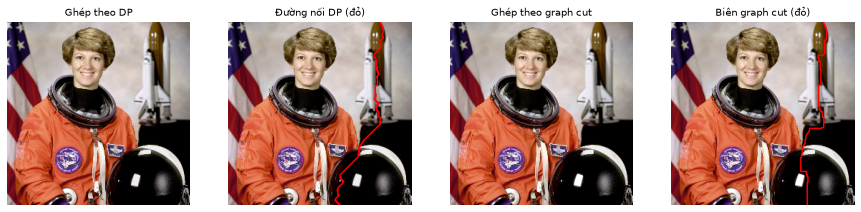

In [8]:
A2, B2 = A[::2, ::2], Bimg[::2, ::2]                                  # giảm một nửa để max-flow chạy nhanh
h2, w2 = A2.shape[:2]
forceA = np.zeros((h2, w2), bool); forceA[:, :40] = True              # 40 cột trái bắt buộc lấy A
forceB = np.zeros((h2, w2), bool); forceB[:, -40:] = True             # 40 cột phải bắt buộc lấy B
cost2 = ((A2.astype(np.float32) - B2.astype(np.float32)) ** 2).sum(axis=2)
band = np.where((np.arange(w2)[None] < 40) | (np.arange(w2)[None] >= w2 - 40), 1e9, cost2)
seam2 = s58.min_error_seam(band)                                      # DP bị buộc đi trong dải tự do
dp_lab = np.arange(w2)[None, :] < seam2[:, None]
import time; t0 = time.perf_counter()
gc_lab, flow = s58.graphcut_labels(A2, B2, forceA, forceB)
t_gc = time.perf_counter() - t0
e_dp, e_gc = s58.labels_energy(dp_lab, A2, B2), s58.labels_energy(gc_lab, A2, B2)
print(f"Năng lượng cắt (tổng chi phí khớp trên các cạnh bị cắt): DP = {e_dp:.0f} | graph cut = {e_gc:.0f} | max-flow = {flow:.0f} | thời gian graph cut {t_gc:.2f}s")
def edge(m):
    e = np.zeros(m.shape, np.uint8)
    e[:, 1:] |= (m[:, 1:] != m[:, :-1]); e[1:, :] |= (m[1:, :] != m[:-1, :])      # chỉ so sánh pixel kề nhau, không cuộn vòng
    return cv2.dilate(e, np.ones((2, 2), np.uint8)).astype(bool)
def with_seam(lab):
    im = s58.labels_composite(lab, A2, B2).copy(); im[edge(lab)] = (255, 0, 0); return im
show([s58.labels_composite(dp_lab, A2, B2), with_seam(dp_lab), s58.labels_composite(gc_lab, A2, B2), with_seam(gc_lab)],
     ["Ghép theo DP", "Đường nối DP (đỏ)", "Ghép theo graph cut", "Biên graph cut (đỏ)"], size=3.2)

**Nhận xét.** Hai phương pháp được so sánh trên **cùng năng lượng** (tổng chi phí khớp các cạnh bị cắt) và cùng ràng buộc (40 cột hai bên cố định). Số liệu in ở trên: graph cut cho năng lượng thấp hơn DP, và bằng giá trị max-flow (định lý max-flow/min-cut, sai khác nhỏ do làm tròn dung lượng thành số nguyên). Điều này không bất ngờ: đường dọc của DP là một nghiệm *khả thi* của bài toán graph cut, nên cực tiểu graph cut không thể tệ hơn. Về hình dạng, đường DP mỗi hàng chỉ có đúng một điểm, còn biên graph cut là đường bất kỳ giữa hai vùng và có thể có đoạn nằm ngang; trên cặp ảnh này hai biên khá giống nhau (cả hai đều né vùng vật thể lạ), nên khác biệt chủ yếu nằm ở con số năng lượng chứ chưa ở hình ảnh. Đổi lại graph cut chậm hơn (giải max-flow trên đồ thị $\sim 10^4$ nút), và chỉ minh họa trên một cặp ảnh tổng hợp.

---
## Phần 2 — Ghép ảnh toàn cảnh (Panorama)

**Pipeline (đề yêu cầu tối thiểu):** tiền xử lý (xám, chuẩn hóa kích thước) → **phát hiện & mô tả đặc trưng** → **so khớp** → **ước lượng homography (RANSAC)** → **warp & căn chỉnh** → **blending vùng chồng lấn**. Chạy *cùng một pipeline* với hai bộ trích xuất đặc trưng **SIFT** và **ORB**, so sánh về độ chính xác căn chỉnh, tính liên tục và chất lượng trực quan.

Vì sao homography? Hai ảnh chụp từ **cùng một vị trí, chỉ xoay camera** liên hệ với nhau qua một phép chiếu $H$ ($3\times3$, 8 DoF, cần ≥ 4 cặp điểm; Chap 04, slide 28/36).

### 2.1 Phát hiện đặc trưng: Harris (Chap 08, slide 14–34)

Đặc trưng tốt phải **duy nhất**: dịch cửa sổ theo mọi hướng đều làm ảnh thay đổi mạnh (góc), khác với vùng phẳng (không đổi) và biên (chỉ đổi theo một hướng). Với xấp xỉ Taylor, sai số dịch $E(u,v)\approx[u\;v]\,H\,[u\;v]^T$, với
$$H=\sum_{W}\begin{bmatrix}I_x^2&I_xI_y\\I_xI_y&I_y^2\end{bmatrix}$$
Điểm đặc trưng: **cả hai trị riêng của $H$ đều lớn**. Toán tử Harris tránh tính căn bậc hai: $R=\det H-k\,\mathrm{tr}(H)^2$. Quy trình: gradient → ma trận $H$ → $R$ → ngưỡng → cực đại địa phương (non-maximum suppression).

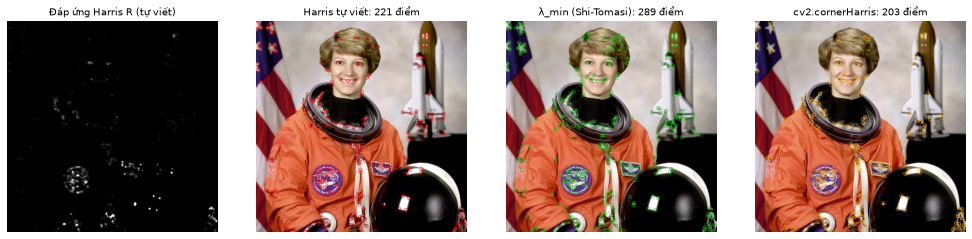

R > 1% max (góc): 3.4% pixel | R < -1% max (biên): 2.5% | còn lại (phẳng): 94.1%
Điểm Harris tự viết có điểm cv2 trong vòng 3 px: 76%


In [9]:
gray = cv2.cvtColor(A, cv2.COLOR_RGB2GRAY)
R, lam_min = s58.harris_response(gray)
pts_harris = s58.local_maxima(R, 0.01, 9)
pts_minlam = s58.local_maxima(np.maximum(lam_min, 0), 0.05, 9)
ref = cv2.cornerHarris(gray.astype(np.float32), 3, 3, 0.04)
pts_cv = s58.local_maxima(ref, 0.01, 9)

def mark(pts, color=(255, 0, 0)):
    out = A.copy()
    for x, y in pts: cv2.circle(out, (int(x), int(y)), 4, color, 1, cv2.LINE_AA)
    return out
Rv = np.clip(R / R.max() * 255 * 4, 0, 255).astype(np.uint8)
show([Rv, mark(pts_harris), mark(pts_minlam, (0, 200, 0)), mark(pts_cv, (255, 160, 0))],
     ["Đáp ứng Harris R (tự viết)", f"Harris tự viết: {len(pts_harris)} điểm", f"λ_min (Shi-Tomasi): {len(pts_minlam)} điểm", f"cv2.cornerHarris: {len(pts_cv)} điểm"], size=3.6)

# Phân loại vùng theo dấu của R: góc (R>0 lớn), biên (R<0), phẳng (|R|~0)
print(f"R > 1% max (góc): {100*(R > 0.01*R.max()).mean():.1f}% pixel | R < -1% max (biên): {100*(R < -0.01*R.max()).mean():.1f}% | còn lại (phẳng): {100*(np.abs(R) <= 0.01*R.max()).mean():.1f}%")
d = np.linalg.norm(pts_harris[:, None, :] - pts_cv[None, :, :], axis=2).min(axis=1)
print(f"Điểm Harris tự viết có điểm cv2 trong vòng 3 px: {100*(d < 3).mean():.0f}%")

**Bất biến (slide 34, 46–48).** Một detector tốt phải tìm lại *cùng các điểm* khi ảnh bị xoay, đổi sáng, đổi tỷ lệ. Ta đo **độ lặp lại (repeatability)**: tỷ lệ điểm tìm được trên ảnh gốc mà sau khi biến đổi vẫn có điểm tìm được trong 3 px. Slide: Harris bất biến với dịch/xoay, **không bất biến với tỷ lệ**; SIFT xử lý tỷ lệ bằng cách tìm cực trị trong không gian tỷ lệ (Laplacian/DoG).

In [10]:
g = gray
def det_harris(im): return s58.local_maxima(s58.harris_response(im)[0], 0.01, 9)
_sift = cv2.SIFT_create()
def det_sift(im): return np.float32([k.pt for k in _sift.detect(im, None)])

def rot(deg): return np.vstack([cv2.getRotationMatrix2D((256, 256), deg, 1.0), [0, 0, 1]])
tests = {"xoay 30°": rot(30), "xoay 90°": rot(90), "thu nhỏ x0.6": np.diag([0.6, 0.6, 1.0]), "thu nhỏ x0.3": np.diag([0.3, 0.3, 1.0]),
         "phóng to x1.6": np.diag([1.6, 1.6, 1.0])}
print(f"{'biến đổi hình học':20s} {'Harris':>8s} {'SIFT':>8s}")
rep = {}
for name, M in tests.items():
    rep[name] = (s58.harris_repeatability(det_harris, g, M), s58.harris_repeatability(det_sift, g, M))
    print(f"{name:20s} {rep[name][0]:8.2f} {rep[name][1]:8.2f}")
# Đổi sáng/tương phản (bất biến quang học): ảnh đổi bằng a*I + b -> không dùng warp
for name, im2 in {"sáng +40": np.clip(g.astype(int) + 40, 0, 255).astype(np.uint8), "tương phản x0.6": (g * 0.6).astype(np.uint8)}.items():
    hr = float((np.linalg.norm(det_harris(g)[:, None] - det_harris(im2)[None], axis=2).min(axis=1) < 3).mean())
    sr = float((np.linalg.norm(det_sift(g)[:, None] - det_sift(im2)[None], axis=2).min(axis=1) < 3).mean())
    print(f"{name:20s} {hr:8.2f} {sr:8.2f}")

biến đổi hình học      Harris     SIFT


xoay 30°                 0.87     0.77


xoay 90°                 1.00     0.94


thu nhỏ x0.6             0.57     0.57


thu nhỏ x0.3             0.39     0.46


phóng to x1.6            0.96     0.68


sáng +40                 0.97     0.93


tương phản x0.6          0.99     0.71


**Nhận xét.** Kết quả khớp slide ở các điểm chính: Harris tìm lại gần như toàn bộ điểm khi **xoay** và khi **đổi sáng/tương phản** (đạo hàm và tương quan cục bộ không phụ thuộc nhiều vào độ sáng tổng), nhưng **repeatability giảm khi thu nhỏ** (0.57 ở ×0.6, thấp hơn nữa ở ×0.3) vì một góc ở tỷ lệ này không còn là góc ở tỷ lệ khác. Hai điều đáng lưu ý về phép đo của ta: (i) phóng to ×1.6 Harris vẫn rất cao vì ảnh phóng to chỉ làm mịn thêm, các góc cũ vẫn là góc; (ii) SIFT **không** vượt Harris trong chỉ số này (thậm chí thấp hơn khi đổi tương phản) vì SIFT loại điểm có tương phản thấp bằng ngưỡng riêng và nhiều keypoint của nó là blob ở tỷ lệ lớn nên vị trí lệch hơn 3 px sau biến đổi. Ưu thế thật sự của SIFT nằm ở **bộ mô tả** (bất biến xoay + chuẩn hóa) và ở khả năng *gán tỷ lệ* cho mỗi điểm, thể hiện ở kết quả so khớp bên dưới chứ không chỉ ở vị trí điểm.

### 2.2 Mô tả đặc trưng và so khớp (Chap 08, slide 44–62)

- **SIFT**: cửa sổ 16×16 quanh điểm, chia lưới 4×4, mỗi ô một histogram 8 hướng gradient ⇒ **128 chiều** (số thực), xoay về hướng chủ đạo (bất biến xoay) và chuẩn hóa (bất biến độ sáng/tương phản). So khớp bằng khoảng cách Euclid.
- **ORB**: mô tả **nhị phân** 256 bit (so sánh cặp pixel), so khớp bằng khoảng cách **Hamming**; rất nhanh, nhưng kém bất biến tỷ lệ/phối cảnh hơn.
- **Khoảng cách tỷ lệ** (slide 57–58): chỉ lấy hàng xóm gần nhất bằng SSD sẽ cho điểm tốt cho cả các khớp mơ hồ; dùng $\frac{d(f_1,f_2)}{d(f_1,f_2')}$ ($f_2'$ là hàng xóm thứ hai) thì khớp mơ hồ có tỷ lệ gần 1 và bị loại (Lowe's ratio test).
- **ROC** (slide 59–62): quét ngưỡng để vẽ TPR–FPR; diện tích dưới đường cong (AUC) càng lớn càng tốt. Ground truth: ta tự làm méo ảnh bằng một homography đã biết, nên biết khớp nào đúng.

SIFT: số điểm 1105 894 | số chiều descriptor: 128 float32


ORB : số điểm 2000 2000 | descriptor: 256 bit uint8


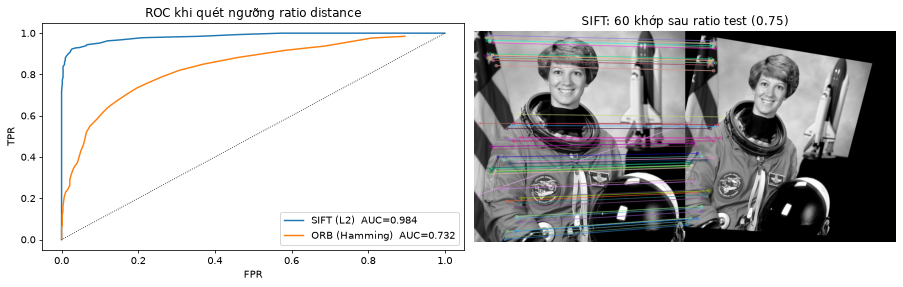

bộ mô tả         điểm ảnh 1  NN đúng (không lọc)  giữ lại (ratio 0.75)  đúng sau lọc    AUC
SIFT (L2)              1105                53.1%                   559         97.5%  0.984
ORB (Hamming)          2000                72.2%                   901         94.2%  0.732


In [11]:
sift = cv2.SIFT_create(); orb = cv2.ORB_create(nfeatures=2000)
H_gt = np.array([[0.9, -0.2, 40], [0.15, 0.95, 10], [2e-4, 1e-4, 1.0]])            # phép chiếu thật giữa hai ảnh
img2 = cv2.warpPerspective(gray, H_gt, gray.shape[::-1])
kp1, d1 = sift.detectAndCompute(gray, None); kp2, d2 = sift.detectAndCompute(img2, None)
print("SIFT: số điểm", len(kp1), len(kp2), "| số chiều descriptor:", d1.shape[1], d1.dtype)
ko1, do1 = orb.detectAndCompute(gray, None); ko2, do2 = orb.detectAndCompute(img2, None)
print("ORB : số điểm", len(ko1), len(ko2), "| descriptor:", do1.shape[1] * 8, "bit", do1.dtype)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
stats = {}
for name, (k1_, k2_, a_, b_, met) in {"SIFT (L2)": (kp1, kp2, d1, d2, "l2"), "ORB (Hamming)": (ko1, ko2, do1, do2, "hamming")}.items():
    fpr, tpr, auc, n_correct, n_total = s58.match_roc(k1_, k2_, a_, b_, H_gt, metric=met)
    ax[0].plot(fpr, tpr, label=f"{name}  AUC={auc:.3f}")
    # Chỉ dùng hàng xóm gần nhất (không ratio test) vs ratio test 0.75
    i1, i2, ratio, nn = s58.match_ratio_test(a_, b_, 0.75, met)
    pts1, pts2 = np.float32([k.pt for k in k1_]), np.float32([k.pt for k in k2_])
    err = np.linalg.norm(sl.apply_homography(H_gt, pts1) - pts2[nn], axis=1)
    acc_all = float((err < 3).mean()); acc_ratio = float((err[i1] < 3).mean()) if len(i1) else 0.0
    stats[name] = (n_total, acc_all, len(i1), acc_ratio, auc)
ax[0].plot([0, 1], [0, 1], "k:", lw=.8); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].set_title("ROC khi quét ngưỡng ratio distance"); ax[0].legend()
vis = cv2.drawMatches(gray, kp1, img2, kp2, [cv2.DMatch(int(i), int(j), 0) for i, j in zip(*s58.match_ratio_test(d1, d2, 0.75)[:2])][:60], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
ax[1].imshow(vis); ax[1].axis("off"); ax[1].set_title("SIFT: 60 khớp sau ratio test (0.75)")
plt.tight_layout(); plt.show()

print(f"{'bộ mô tả':16s} {'điểm ảnh 1':>10s} {'NN đúng (không lọc)':>20s} {'giữ lại (ratio 0.75)':>21s} {'đúng sau lọc':>13s} {'AUC':>6s}")
for n, (nt, aa, nk, ar, auc_) in stats.items():
    print(f"{n:16s} {nt:10d} {aa * 100:19.1f}% {nk:21d} {ar * 100:12.1f}% {auc_:6.3f}")

### 2.3 Ước lượng homography: RANSAC (Chap 04, slide 32–36)

Ngay cả sau ratio test vẫn lẫn khớp sai (outlier) và một khớp sai kéo lệch cả nghiệm bình phương tối thiểu. **RANSAC** lặp: chọn ngẫu nhiên 4 cặp → tính $H$ → đếm số *inlier* (sai số chiếu < ngưỡng) → giữ mô hình tốt nhất rồi tinh chỉnh trên toàn bộ inlier. So sánh trên các cặp view thật của bộ ảnh panorama: (a) bình phương tối thiểu trên *tất cả* khớp, (b) RANSAC tự viết, (c) `cv2.findHomography`.

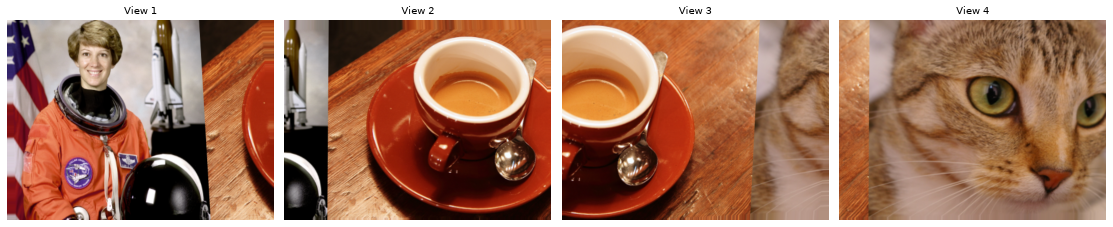

cặp     #khớp  LS (tất cả)   RANSAC tự viết   cv2 RANSAC   (sai số chuyển vị góc ảnh, px, so với homography thật)


1-2       195      1014.18       0.14 (189/195)         0.14


D:\git_pet\computer-vision\CO3057-BTL_17\src\slides_ch02_04.py:200: RuntimeWarning: divide by zero encountered in divide
  return p[:, :2] / p[:, 2:3]
D:\git_pet\computer-vision\CO3057-BTL_17\src\slides_ch02_04.py:200: RuntimeWarning: invalid value encountered in divide
  return p[:, :2] / p[:, 2:3]


2-3       111       755.82       0.48 (101/111)         0.27


3-4        68       483.72       0.35 (63/68)         0.34


In [12]:
# Các thí nghiệm có đáp án dùng cảnh tổng hợp, không phụ thuộc ảnh thật trong data/p2_panorama/
scene = pano.build_ground_truth_scene()
views = pano.synthesize_views(scene, n_views=4)
H_gt_list = s58.synthetic_view_homographies(scene.shape[1], n_views=len(views), height=scene.shape[0])
W_v, H_v = views[0].shape[1], views[0].shape[0]
show(views, [f"View {i + 1}" for i in range(len(views))], size=4)

def pair_data(i, method="sift"):
    k1, d1_ = pano.detect_and_describe(views[i - 1], method); k2, d2_ = pano.detect_and_describe(views[i], method)
    m = pano.match_features(d1_, d2_, method)
    return np.float32([k1[x.queryIdx].pt for x in m]), np.float32([k2[x.trainIdx].pt for x in m])   # (điểm view i-1, điểm view i)

# Homography thật giữa view i và view i-1: H_{i->i-1} = inv(H_{i-1->0}) · H_{i->0}
gt_pair = lambda i: np.linalg.inv(H_gt_list[i - 1]) @ H_gt_list[i]
print(f"{'cặp':6s} {'#khớp':>6s} {'LS (tất cả)':>12s} {'RANSAC tự viết':>16s} {'cv2 RANSAC':>12s}   (sai số chuyển vị góc ảnh, px, so với homography thật)")
for i in range(1, len(views)):
    p1, p2 = pair_data(i)
    H_ls = sl.fit_homography(p2, p1)
    H_r, inl = sl.ransac_homography(p2, p1, thresh=4.0)
    H_c, _ = cv2.findHomography(p2, p1, cv2.RANSAC, 4.0)
    e = lambda H: s58.corner_transfer_error(H, gt_pair(i), W_v, H_v)
    print(f"{i}-{i + 1:<4d} {len(p1):6d} {e(H_ls):12.2f} {e(H_r):10.2f} ({int(inl.sum())}/{len(p1)}) {e(H_c):12.2f}")

### 2.4 Pipeline hoàn chỉnh: SIFT vs ORB (đề: so sánh độ chính xác căn chỉnh, tính liên tục, chất lượng trực quan)

Pipeline `pano.stitch_sequence`: phát hiện/mô tả → ratio test → homography RANSAC → ghép chuỗi $H_{i\to0}=H_{i-1\to0}H_{i\to i-1}$ → warp toàn bộ lên một canvas → **feather blending** (trọng số theo khoảng cách tới biên mỗi ảnh). Vì biết homography thật nên có thêm thước đo **sai số căn chỉnh** (px) của từng view so với view đầu.

In [13]:
results = {}
for method in ["sift", "orb"]:
    t0 = time.time(); res = pano.stitch_sequence(views, method=method); res["time"] = time.time() - t0
    res["align_err"] = [s58.corner_transfer_error(res["homographies"][i], H_gt_list[i], W_v, H_v) for i in range(len(views))]
    results[method] = res
    print(f"[{method.upper()}] {res['time']:.2f}s | điểm/view: {res['keypoint_counts']}")
    for st in res["pair_stats"]:
        print(f"   cặp {st['pair']}: {st['matches']} khớp, {st['inliers']} inlier ({st['inlier_ratio'] * 100:.1f}%)")
    print("   sai số căn chỉnh so với thật (px) theo view:", [round(e, 2) for e in res["align_err"]])

[SIFT] 0.26s | điểm/view: [913, 528, 345, 633]
   cặp (0, 1): 195 khớp, 189 inlier (96.9%)
   cặp (1, 2): 111 khớp, 100 inlier (90.1%)
   cặp (2, 3): 68 khớp, 63 inlier (92.6%)
   sai số căn chỉnh so với thật (px) theo view: [0.0, 0.14, 0.25, 0.81]
[ORB] 0.18s | điểm/view: [1935, 1503, 939, 990]
   cặp (0, 1): 105 khớp, 95 inlier (90.5%)
   cặp (1, 2): 282 khớp, 276 inlier (97.9%)
   cặp (2, 3): 46 khớp, 37 inlier (80.4%)
   sai số căn chỉnh so với thật (px) theo view: [0.0, 1.63, 9.58, 26.5]


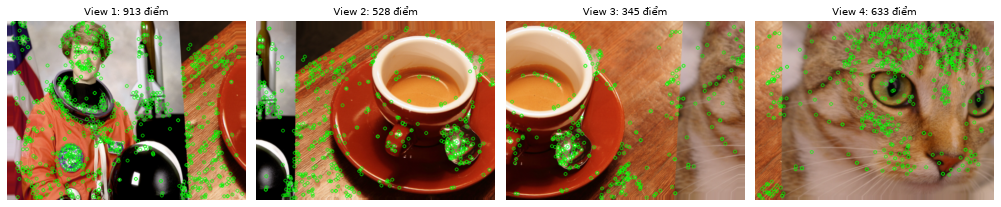

<Figure size 448x336 with 0 Axes>

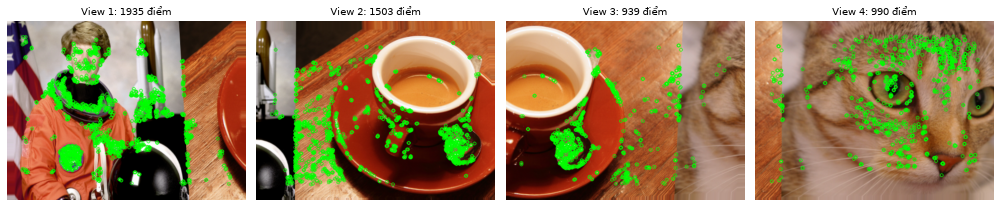

<Figure size 448x336 with 0 Axes>

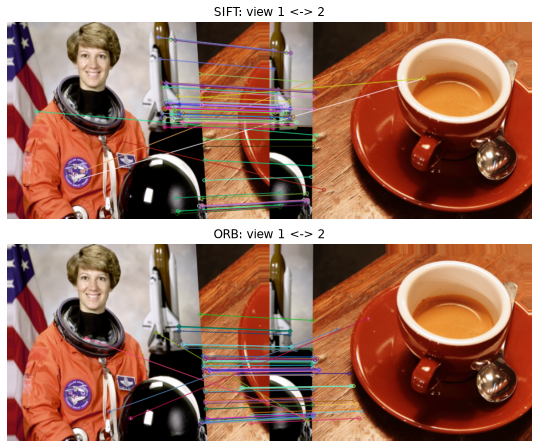

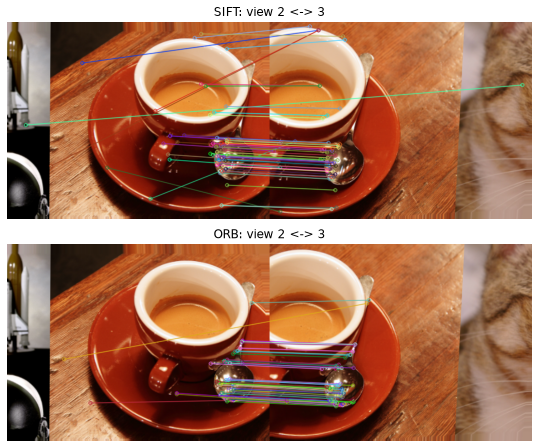

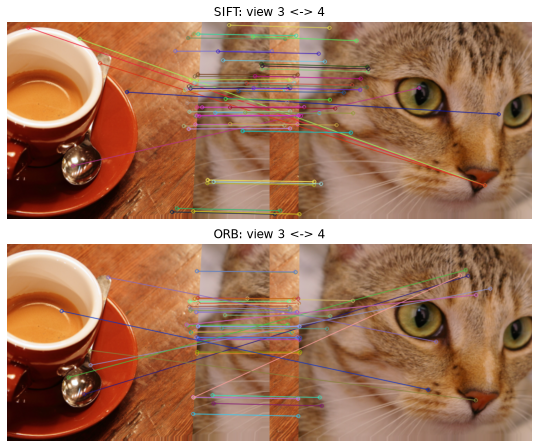

In [14]:
for method in ["sift", "orb"]:
    show(results[method]["keypoints_viz"], [f"View {i + 1}: {c} điểm" for i, c in enumerate(results[method]["keypoint_counts"])], size=3.6)
    plt.suptitle(f"Điểm đặc trưng ({method.upper()})"); plt.show()
for i, (vs, vo) in enumerate(zip(results["sift"]["matches_viz"], results["orb"]["matches_viz"])):
    fig, ax = plt.subplots(2, 1, figsize=(10, 6.5))
    ax[0].imshow(vs); ax[0].set_title(f"SIFT: view {i + 1} <-> {i + 2}"); ax[1].imshow(vo); ax[1].set_title(f"ORB: view {i + 1} <-> {i + 2}")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()

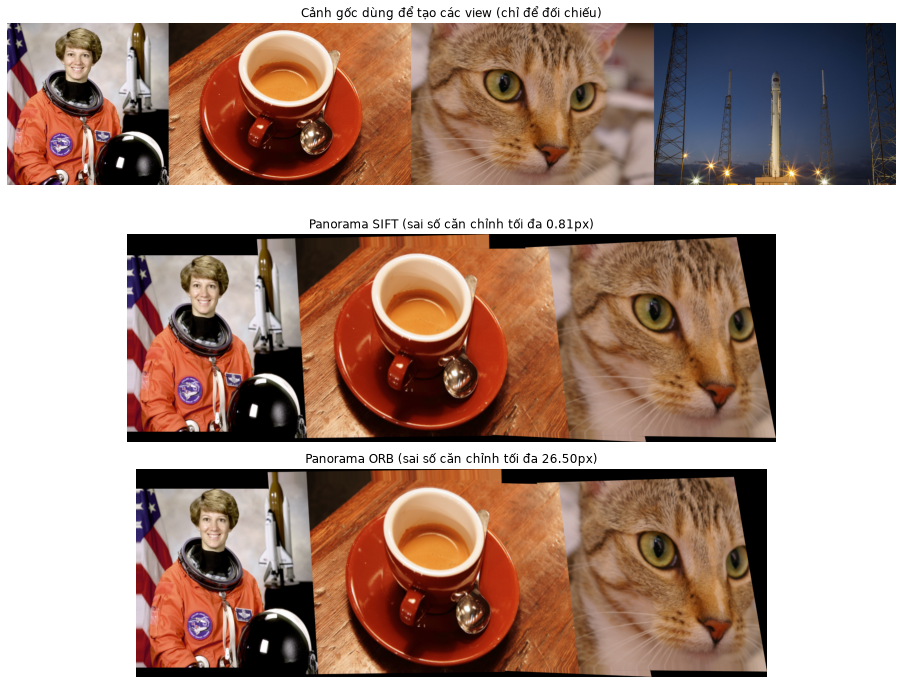

cv2.Stitcher tham chiếu: OK, kích thước (362, 985, 3)
Kích thước panorama tự viết: SIFT (425, 1325, 3) | ORB (419, 1271, 3)


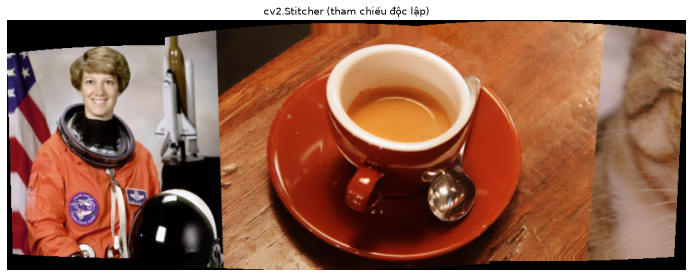

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(13, 10))
axes[0].imshow(scene); axes[0].set_title("Cảnh gốc dùng để tạo các view (chỉ để đối chiếu)")
axes[1].imshow(results["sift"]["panorama"]); axes[1].set_title(f"Panorama SIFT (sai số căn chỉnh tối đa {max(results['sift']['align_err']):.2f}px)")
axes[2].imshow(results["orb"]["panorama"]); axes[2].set_title(f"Panorama ORB (sai số căn chỉnh tối đa {max(results['orb']['align_err']):.2f}px)")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

status, ref_pano = pano.opencv_reference_stitch(views)
print("cv2.Stitcher tham chiếu:", "OK, kích thước" if status == cv2.Stitcher_OK else f"thất bại, status={status}", ref_pano.shape if ref_pano is not None else "")
print("Kích thước panorama tự viết: SIFT", results["sift"]["panorama"].shape, "| ORB", results["orb"]["panorama"].shape)
if ref_pano is not None:
    show([ref_pano], ["cv2.Stitcher (tham chiếu độc lập)"], size=10)

### 2.5 Xử lý vùng chồng lấn: không blend vs feather (Chap 05, slide 8)

Ghi đè (view sau đè lên view trước) là mức cơ bản nhất; feathering trộn theo khoảng cách tới biên mỗi ảnh. Lưu ý: các view của bộ tổng hợp được cắt từ *cùng một cảnh* nên **không có chênh lệch phơi sáng** — ở dữ liệu chụp thật, ghi đè sẽ lộ thêm các bước nhảy sáng/tối rõ hơn nhiều.

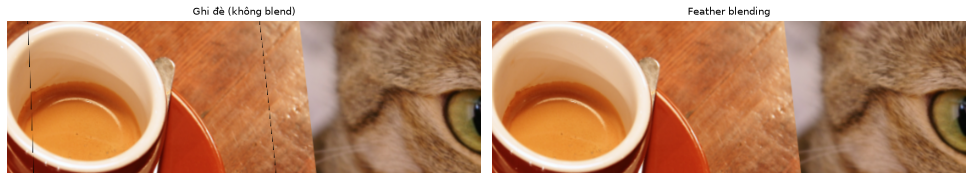

Gradient ngang trung bình trong vùng zoom: ghi đè = 3.94 | feather = 3.50


In [16]:
over = pano.stitch_sequence(views, method="sift", blend="overwrite")["panorama"]
feat = results["sift"]["panorama"]
# vùng chồng lấn view 2-3: lấy một dải ngang chứa đường nối
x0 = int(0.42 * 0 + (len(views) - 2) * 480 * 0.58 - 40)
box = (slice(40, 220), slice(x0, x0 + 560))
show([over[box], feat[box]], ["Ghi đè (không blend)", "Feather blending"], size=7)
d_seam = lambda im: float(np.abs(np.diff(cv2.cvtColor(im, cv2.COLOR_RGB2GRAY).astype(np.float32), axis=1)).mean())
print(f"Gradient ngang trung bình trong vùng zoom: ghi đè = {d_seam(over[box]):.2f} | feather = {d_seam(feat[box]):.2f}")

### 2.6 Khi nào thành công, khi nào thất bại? (đề: phân tích các bộ ảnh và các trường hợp khó)

Quét **mức chồng lấn** giữa hai view (0.50 → 0.05) và so sánh SIFT/ORB bằng số inlier và sai số căn chỉnh thật; sau đó thử một bộ ảnh **kết cấu lặp** (bàn cờ) — kịch bản khó vì nhiều vùng giống hệt nhau nên so khớp mơ hồ.

 overlap |     SIFT: khớp/inlier/lỗi px |      ORB: khớp/inlier/lỗi px
    0.50 |         244 /  233 /    0.15 |         230 /  218 /    7.59
    0.35 |         160 /  156 /    0.57 |          82 /   69 /    5.12
    0.25 |         118 /  115 /    0.18 |          27 /   12 /   93.51
    0.15 |          54 /   49 /    0.74 |          21 /    6 /  330.12
    0.08 |          18 /   12 /    5.14 |          11 /    6 /  594.23
    0.04 |           7 /    4 /  350.90 |          13 /    4 /  876.99


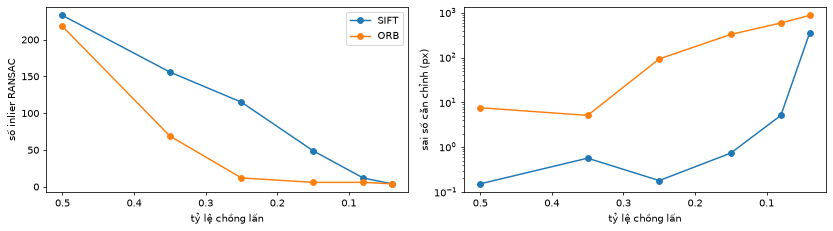

In [17]:
def pair_experiment(scene_img, method, overlap, n_views=2, seed=0):
    vws = pano.synthesize_views(scene_img, n_views=n_views, overlap=overlap, seed=seed)
    gts = s58.synthetic_view_homographies(scene_img.shape[1], n_views=n_views, overlap=overlap, height=scene_img.shape[0], seed=seed)
    k1, d1_ = pano.detect_and_describe(vws[0], method); k2, d2_ = pano.detect_and_describe(vws[1], method)
    if d1_ is None or d2_ is None: return 0, 0, float("nan")
    m = pano.match_features(d1_, d2_, method)
    H, mask_in = pano.estimate_homography(k1, k2, m)
    if H is None: return len(m), 0, float("nan")
    return len(m), int(mask_in.sum()), s58.corner_transfer_error(H, np.linalg.inv(gts[0]) @ gts[1], 480, scene_img.shape[0])

overlaps = [0.5, 0.35, 0.25, 0.15, 0.08, 0.04]
table = {m: [pair_experiment(scene, m, ov) for ov in overlaps] for m in ("sift", "orb")}
print(f"{'overlap':>8s} | {'SIFT: khớp/inlier/lỗi px':>28s} | {'ORB: khớp/inlier/lỗi px':>28s}")
for k, ov in enumerate(overlaps):
    f = lambda t: f"{t[0]:5d} /{t[1]:5d} /{t[2]:8.2f}"
    print(f"{ov:8.2f} | {f(table['sift'][k]):>28s} | {f(table['orb'][k]):>28s}")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
for m, c in (("sift", "tab:blue"), ("orb", "tab:orange")):
    ax[0].plot(overlaps, [t[1] for t in table[m]], "o-", color=c, label=m.upper()); ax[1].plot(overlaps, [t[2] for t in table[m]], "o-", color=c, label=m.upper())
ax[0].set_xlabel("tỷ lệ chồng lấn"); ax[0].set_ylabel("số inlier RANSAC"); ax[1].set_xlabel("tỷ lệ chồng lấn"); ax[1].set_ylabel("sai số căn chỉnh (px)"); ax[1].set_yscale("log")
ax[0].legend(); ax[0].invert_xaxis(); ax[1].invert_xaxis(); plt.tight_layout(); plt.show()

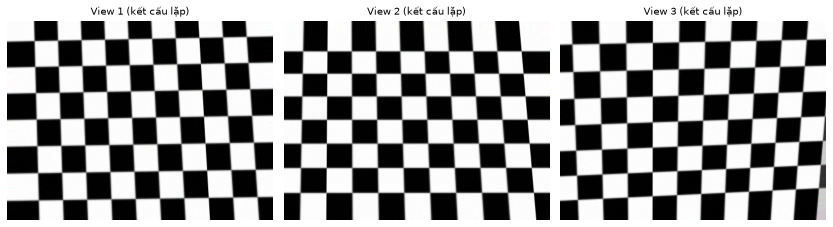

[SIFT] pipeline thất bại: Not enough good matches between view 1 and view 2 (sift).
[ORB] inlier/khớp: [(8, 236), (9, 251)] | sai số căn chỉnh (px): [0.0, 393.2, 623.5]


In [18]:
# Bộ ảnh khó: kết cấu lặp (bàn cờ) -- nhiều vùng giống nhau => khớp mơ hồ
tile = cv2.resize(cv2.cvtColor(img_as_ubyte(data.checkerboard()), cv2.COLOR_GRAY2RGB), (360, 360), interpolation=cv2.INTER_AREA)
scene_rep = np.hstack([tile] * 6)
rng = np.random.default_rng(0)
scene_rep = np.clip(scene_rep.astype(np.int16) + rng.normal(0, 4, scene_rep.shape), 0, 255).astype(np.uint8)    # nhiễu nhẹ để có chi tiết cục bộ
views_rep = pano.synthesize_views(scene_rep, n_views=3)
gts_rep = s58.synthetic_view_homographies(scene_rep.shape[1], n_views=3, height=scene_rep.shape[0])
show(views_rep, [f"View {i + 1} (kết cấu lặp)" for i in range(3)], size=4)
for m in ("sift", "orb"):
    try:
        res = pano.stitch_sequence(views_rep, method=m)
        errs = [s58.corner_transfer_error(res["homographies"][i], gts_rep[i], 480, 360) for i in range(3)]
        print(f"[{m.upper()}] inlier/khớp:", [(s['inliers'], s['matches']) for s in res["pair_stats"]], "| sai số căn chỉnh (px):", [round(e, 1) for e in errs])
    except RuntimeError as e:
        print(f"[{m.upper()}] pipeline thất bại: {e}")

### 2.7 Độ bền với nhiễu cảm biến và lệch phơi sáng

Dữ liệu tổng hợp ở trên "sạch": không lệch sáng, không nhiễu. Ảnh chụp thật có cả hai. Ta mô phỏng bằng cách nhân mỗi view với một **hệ số phơi sáng** khác nhau (0.75–1.25, như bật/tắt auto-exposure giữa các lần chụp) và/hoặc cộng **nhiễu Gauss** σ = 5/10/15, rồi đo lại sai số căn chỉnh so với ground truth. (Méo ống kính không được thử: ground truth ở đây là homography, mà méo ống kính làm quan hệ giữa hai view không còn là homography nên không có "đáp án" để so sánh công bằng.)

điều kiện              SIFT: sai số căn chỉnh (px) view 2/3/4            ORB: view 2/3/4


sạch                                    0.1 /    0.3 /    0.8      1.6 /    9.6 /   26.5


lệch phơi sáng                          0.2 /    1.1 /    2.2      2.0 /    4.1 /    9.2


nhiễu σ=5                               0.2 /    5.3 /   15.4      7.8 /   26.3 /   73.0


nhiễu σ=10                              1.0 /    7.8 /   19.8     16.9 /   53.7 /  151.8


nhiễu σ=15                              1.3 /    9.5 /   26.3      4.9 /   11.0 /   33.9


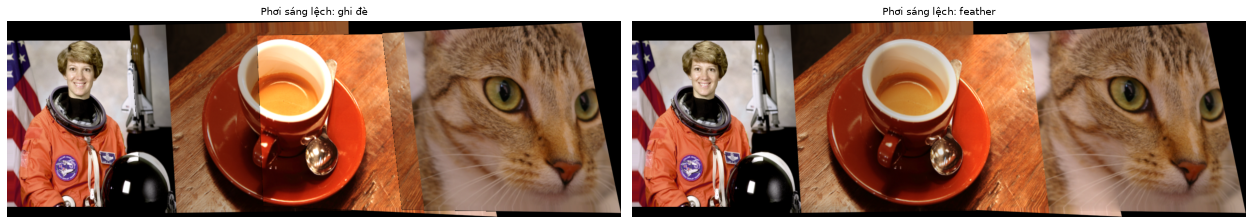

In [19]:
def perturb(vws, gain=None, noise=0.0):
    out = []
    for i, v in enumerate(vws):
        im = v.astype(np.float32)
        if gain: im = im * gain[i]
        if noise: im = im + np.random.default_rng(i).normal(0, noise, im.shape)
        out.append(np.clip(im, 0, 255).astype(np.uint8))
    return out

gains = [1.0, 0.75, 1.25, 0.9]
conds = {"sạch": {}, "lệch phơi sáng": dict(gain=gains), "nhiễu σ=5": dict(noise=5), "nhiễu σ=10": dict(noise=10), "nhiễu σ=15": dict(noise=15)}
print(f"{'điều kiện':18s} {'SIFT: sai số căn chỉnh (px) view 2/3/4':>42s} {'ORB: view 2/3/4':>26s}")
robust = {}
for cname, kw in conds.items():
    row = []
    for m in ("sift", "orb"):
        try:
            r = pano.stitch_sequence(perturb(views, **kw), method=m)
            errs = [s58.corner_transfer_error(r["homographies"][i], H_gt_list[i], W_v, H_v) for i in range(1, len(views))]
            row.append(" / ".join(f"{e:6.1f}" for e in errs)); robust[(cname, m)] = r
        except RuntimeError:
            row.append("thất bại")
    print(f"{cname:18s} {row[0]:>42s} {row[1]:>26s}")

# Với phơi sáng lệch, đường nối giữa các view: ghi đè vs feather
vg = perturb(views, gain=gains)
over_g = pano.stitch_sequence(vg, method="sift", blend="overwrite")["panorama"]
feat_g = pano.stitch_sequence(vg, method="sift", blend="feather")["panorama"]
show([over_g, feat_g], ["Phơi sáng lệch: ghi đè", "Phơi sáng lệch: feather"], size=9)

**Nhận xét (đối chiếu số liệu ở các ô trên).**
- **Độ chính xác căn chỉnh.** Trên bộ sạch SIFT sai số dưới ~1 px ở view xa nhất, ORB lệch dần (26.5 px ở view 4) — sai số *cộng dồn* qua các phép nhân $H_{i-1\to0}H_{i\to i-1}$, nên lỗi ở cặp đầu bị khuếch đại ở các view sau. Đây là thước đo quan trọng hơn việc nhìn panorama bằng mắt, vì lệch vài pixel khó thấy khi feather làm mờ. **Nhưng sai số của ORB có phương sai rất lớn**: cùng bộ ảnh, thêm lệch phơi sáng lại cho sai số *nhỏ hơn* (9.2 px) và nhiễu σ=10 cho 151.8 px còn σ=15 chỉ 33.9 px (mục 2.7, mỗi điều kiện chỉ một lần thực hiện nhiễu). Cặp view (2,3) của ORB chỉ có 46 khớp nên một vài khớp sai đủ làm lệch cả chuỗi. Vì vậy kết luận an toàn là *SIFT ổn định hơn ORB về căn chỉnh trong thí nghiệm này*, không phải "ORB luôn lệch X px"; muốn xếp hạng chắc chắn cần lặp nhiều bộ ảnh/seed như đã làm ở benchmark phân vùng.
- **Tính liên tục & chất lượng trực quan.** Với căn chỉnh tốt (SIFT), ghi đè chỉ để lại các đường mảnh sẫm ở mép ảnh sau warp (nội suy ra ngoài biên) và feather xóa gần hết chúng; bộ tổng hợp không có chênh lệch phơi sáng nên không thấy bước nhảy sáng. Nếu căn chỉnh lệch (ORB, hàng chục pixel ở view xa) thì vùng chồng lấn bị lệch/bóng kép — blending **không sửa được** căn chỉnh sai.
- **Ưu/nhược.** SIFT: bất biến tỷ lệ/xoay/sáng, mô tả 128 chiều có độ phân biệt cao (AUC ROC ≈ 0.98 so với ≈ 0.73 của ORB trong thí nghiệm ở 2.2), nặng hơn (số thực 128 chiều) nhưng ở quy mô ảnh này vẫn chạy cỡ vài phần mười giây. ORB: nhị phân 256 bit, so khớp Hamming gọn và nhanh, cho nhiều điểm hơn, độ chính xác sau ratio test vẫn cao (≈ 94%) nhưng khó chọn ngưỡng tách khớp đúng/sai (AUC thấp), và kém bền hơn khi chồng lấn ít hoặc có biến dạng phối cảnh — thấy rõ ở bảng quét chồng lấn: ORB đã lệch vài px ở overlap 0.5 và hỏng từ 0.25, SIFT còn dưới ~1 px đến overlap 0.15.
- **Độ bền với nhiễu và phơi sáng (2.7).** Lệch phơi sáng giữa các view ít ảnh hưởng căn chỉnh của SIFT (2.2 px ở view 4, so với 0.8 px sạch) vì descriptor được chuẩn hóa độ sáng/tương phản. **Nhiễu cảm biến mới là điểm yếu của cả hai**: chỉ σ=5 (≈ 2% dải sáng) đã làm sai số của SIFT ở view 4 tăng từ 0.8 lên 15.4 px, và ORB (so sánh cặp pixel nhạy nhiễu) hỏng nặng hơn (73 px). Gợi ý thực tế: khử nhiễu nhẹ (Gaussian/bilateral) *trước* khi phát hiện đặc trưng, nhất là khi dùng ORB. Méo ống kính không được đánh giá vì ground truth homography không còn đúng; hiệu chỉnh ống kính trước khi ghép là điều kiện của mô hình homography.
- **Trường hợp khó.** Khi chồng lấn giảm, số khớp và inlier giảm nhanh; dưới một ngưỡng (thấy trong bảng quét) homography không còn ước lượng được hoặc sai nặng. Cảnh kết cấu lặp làm ratio test loại gần hết khớp hoặc cho khớp lệch chu kỳ; homography chỉ đúng cho cảnh phẳng/camera xoay quanh tâm quang học nên cảnh có chiều sâu hoặc vật thể chuyển động sẽ cho ghost.
- **Lưu ý về dữ liệu.** Các view được tổng hợp từ ảnh mẫu bằng phép chiếu đã biết nên đánh giá khách quan được; ảnh chụp thật sẽ có thêm méo ống kính, đổi phơi sáng và chuyển động, nên với dữ liệu thật nên kết hợp thêm chỉnh sáng/gradient-domain ở bước blending.

---
## Tổng kết

- **Phần 1** — Poisson/gradient-domain loại bỏ quầng lệch màu mà ghép trực tiếp và feather không làm được, bằng cách giữ *gradient* của nguồn và ghim biên về nền; seam score và độ lệch màu quanh viền được đo bằng số. Ví dụ 1-D cho thấy cả ý tưởng lẫn giới hạn (không giữ nổi mọi gradient khi điều kiện biên mâu thuẫn). Khi có vật thể di chuyển, đường cắt tối ưu DP tránh bóng ma tốt hơn trộn.
- **Phần 2** — pipeline đầy đủ Harris/SIFT/ORB → ratio test → RANSAC → warp → feather, được **kiểm chứng bằng ground truth**: SIFT chính xác và ổn định hơn ORB, ORB nhanh/gọn hơn; chất lượng giảm mạnh khi chồng lấn ít hoặc cảnh có kết cấu lặp; RANSAC là bước then chốt để loại khớp sai.

Hình của các script (`python src/p2_gradient_domain.py`, `python src/p2_panorama.py`) vẫn được lưu ở `outputs/p2_gradient_domain` và `outputs/p2_panorama` để nhúng vào báo cáo; xem thêm `report/REPORT_TEMPLATE_2.md`.